# Pixel embedding resource analysis

Parse every request recorded in `pixellogs/*.txt` and compare the three embedding inputs: **image**, **text** (logged as JSON only), and **image+text** (logged as Image + JSON).

A run is usable only when all three embedding requests completed. `pixel.py` writes a `[RUN INVALID]` notice when any request fails, and the parser excludes the entire log rather than retaining its other modalities. For compatibility, legacy logs with a non-2xx HTTP status, a nonzero exit code, or an incomplete request set are excluded too. Missing memory fields remain `NaN`, so otherwise-valid older logs still contribute to time and power statistics.

In [1]:
from pathlib import Path
import re

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 140)

LOG_DIR = Path("pixellogs")
EMBEDDING_ORDER = ["image", "text", "image+text"]
LABEL_TO_TYPE = {
    "Image only": "image",
    "JSON only": "text",
    "Image + JSON": "image+text",
}


## Parser

Parsing is request-section based because the detailed sections contain the newer RSS fields. Validity is file-wide: any `[RUN INVALID]` notice or incomplete/failed request excludes all modalities in that log. `VmHWM` is the process-lifetime resident-set high-water mark; the log labels make clear that it includes model startup as well as the request.

In [2]:
NUMBER = r"([-+]?(?:\d+(?:\.\d*)?|\.\d+)(?:[eE][-+]?\d+)?)"
REQUEST_RE = re.compile(
    r"^=== Request\s+\d+/\d+:\s*(.*?)\s*===\s*$",
    re.MULTILINE,
)

# Patterns are deliberately tied to units so that the two Energy consumption
# lines (mWh and J) cannot be confused with one another.
NUMERIC_FIELDS = {
    "embedding_dimensions": rf"^\[RESULT\] Embedding dimensions:\s*{NUMBER}\s*$",
    "response_time_s": rf"^\[RESULT\] Response time:\s*{NUMBER}\s*seconds\s*$",
    "charge_used_uah": rf"^\[RESULT\] Battery charge used:\s*{NUMBER}\s*microamp-hours\s*$",
    "mean_voltage_v": rf"^\[RESULT\] Mean battery voltage:\s*{NUMBER}\s*V\s*$",
    "energy_mwh": rf"^\[RESULT\] Energy consumption:\s*{NUMBER}\s*mWh\s*$",
    "energy_j": rf"^\[RESULT\] Energy consumption:\s*{NUMBER}\s*J\s*$",
    "average_power_w": rf"^\[RESULT\] Average power:\s*{NUMBER}\s*W\s*$",
    "current_before_ma": rf"^\[RESULT\] Battery current before:\s*{NUMBER}\s*mA\s*$",
    "current_after_ma": rf"^\[RESULT\] Battery current after:\s*{NUMBER}\s*mA\s*$",
    "rss_before_mib": rf"^\[RESULT\] Process RSS before request:\s*{NUMBER}\s*MiB(?:\s*\[PID\s+\d+\])?\s*$",
    "rss_after_mib": rf"^\[RESULT\] Process RSS after request:\s*{NUMBER}\s*MiB(?:\s*\[PID\s+\d+\])?\s*$",
    "peak_rss_mib": rf"^\[RESULT\] Process peak RSS \(startup \+ request, VmHWM\):\s*{NUMBER}\s*MiB(?:\s*\[PID\s+\d+\])?\s*$",
}
NUMERIC_FIELDS = {
    name: re.compile(pattern, re.MULTILINE)
    for name, pattern in NUMERIC_FIELDS.items()
}
METHOD_RE = re.compile(
    r"^\[RESULT\] Measurement method:\s*(.+?)\s*$", re.MULTILINE
)
RUN_ID_RE = re.compile(r"^Run ID:\s*(\d+)\s*$", re.MULTILINE)
STARTED_RE = re.compile(r"^Started:\s*(.+?)\s*$", re.MULTILINE)
EXIT_RE = re.compile(r"^Exit code:\s*(-?\d+)\s*$", re.MULTILINE)
HTTP_STATUS_RE = re.compile(r"^\[HTTP\] Status code:\s*(\d+)\s*$", re.MULTILINE)
INVALID_NOTICE_RE = re.compile(r"^\[RUN INVALID\].*$", re.MULTILINE)


def _numeric_value(pattern, section):
    match = pattern.search(section)
    return float(match.group(1)) if match else np.nan


def read_log_text(path):
    """Decode PowerShell UTF-16 logs and ordinary UTF-8 logs."""
    raw = path.read_bytes()
    if raw.startswith((b"\xff\xfe", b"\xfe\xff")):
        return raw.decode("utf-16", errors="replace")
    return raw.decode("utf-8-sig", errors="replace")


def parse_pixel_log(path):
    """Return (request rows, log metadata) parsed from one Pixel log."""
    text = read_log_text(path)
    run_match = RUN_ID_RE.search(text)
    run_id = int(run_match.group(1)) if run_match else (
        int(path.stem) if path.stem.isdigit() else path.stem
    )
    started_match = STARTED_RE.search(text)
    exit_match = EXIT_RE.search(text)
    headings = list(REQUEST_RE.finditer(text))
    invalid_notice = INVALID_NOTICE_RE.search(text)
    http_statuses = [int(value) for value in HTTP_STATUS_RE.findall(text)]

    metadata = {
        "run_id": run_id,
        "log_file": path.name,
        "started": started_match.group(1) if started_match else None,
        "exit_code": int(exit_match.group(1)) if exit_match else pd.NA,
        "has_summary": "=== Summary ===" in text,
        "request_sections": len(headings),
        "invalid_notice": invalid_notice.group(0) if invalid_notice else None,
    }

    rows = []
    for index, heading in enumerate(headings):
        end = headings[index + 1].start() if index + 1 < len(headings) else len(text)
        section = text[heading.end():end]
        raw_label = heading.group(1).strip()
        row = {
            "run_id": run_id,
            "log_file": path.name,
            "request_number": index + 1,
            "request_label": raw_label,
            "embedding_type": LABEL_TO_TYPE.get(raw_label, raw_label.lower()),
            "log_has_summary": metadata["has_summary"],
            "log_exit_code": metadata["exit_code"],
        }
        row.update({
            name: _numeric_value(pattern, section)
            for name, pattern in NUMERIC_FIELDS.items()
        })
        method_match = METHOD_RE.search(section)
        row["measurement_method"] = (
            method_match.group(1).strip() if method_match else None
        )
        required = ("response_time_s", "energy_mwh", "average_power_w")
        row["request_complete"] = all(pd.notna(row[field]) for field in required)
        row["rss_delta_mib"] = (
            row["rss_after_mib"] - row["rss_before_mib"]
            if pd.notna(row["rss_after_mib"]) and pd.notna(row["rss_before_mib"])
            else np.nan
        )
        rows.append(row)

    metadata["complete_requests"] = sum(row["request_complete"] for row in rows)
    expected_labels = set(LABEL_TO_TYPE)
    observed_labels = {row["request_label"] for row in rows}
    complete_request_set = (
        len(rows) == len(expected_labels)
        and observed_labels == expected_labels
        and all(row["request_complete"] for row in rows)
    )
    exit_code = metadata["exit_code"]
    if invalid_notice:
        invalid_reason = invalid_notice.group(0)
    elif any(status < 200 or status >= 300 for status in http_statuses):
        invalid_reason = f"legacy non-2xx HTTP status: {http_statuses}"
    elif pd.notna(exit_code) and exit_code != 0:
        invalid_reason = f"legacy nonzero exit code: {exit_code}"
    elif rows and not complete_request_set:
        invalid_reason = "incomplete three-request set"
    else:
        invalid_reason = None
    metadata["run_invalid"] = invalid_reason is not None
    metadata["invalid_reason"] = invalid_reason
    return rows, metadata


In [3]:
if not LOG_DIR.is_dir():
    raise FileNotFoundError(f"Pixel log directory not found: {LOG_DIR.resolve()}")

def log_sort_key(path):
    return (0, int(path.stem)) if path.stem.isdigit() else (1, path.name)

request_rows = []
log_rows = []
for log_path in sorted(LOG_DIR.glob("*.txt"), key=log_sort_key):
    rows, metadata = parse_pixel_log(log_path)
    if not metadata["run_invalid"]:
        request_rows.extend(rows)
    log_rows.append(metadata)

all_requests = pd.DataFrame(request_rows)
logs = pd.DataFrame(log_rows)
measurements = all_requests.loc[all_requests["request_complete"]].copy()
measurements["embedding_type"] = pd.Categorical(
    measurements["embedding_type"], categories=EMBEDDING_ORDER, ordered=True
)
measurements = measurements.sort_values(["run_id", "embedding_type"]).reset_index(drop=True)

print(f"Log files: {len(logs):,}")
print(f"Accepted request sections: {len(all_requests):,}")
print(f"Usable completed requests: {len(measurements):,}")
print(f"Invalid log files excluded: {logs['run_invalid'].sum():,}")


Log files: 447
Accepted request sections: 1,269
Usable completed requests: 1,269
Invalid log files excluded: 7


## Data-quality and coverage audit

Counts are shown separately for each metric because memory was added later. Every included run has a complete image, text, and image+text request; logs marked invalid (including legacy failures inferred by the parser) contribute no measurements.

In [4]:
coverage = (
    measurements.groupby("embedding_type", observed=False)
    .agg(
        requests=("run_id", "size"),
        time_n=("response_time_s", "count"),
        energy_n=("energy_mwh", "count"),
        power_n=("average_power_w", "count"),
        rss_before_n=("rss_before_mib", "count"),
        rss_after_n=("rss_after_mib", "count"),
        peak_rss_n=("peak_rss_mib", "count"),
    )
)
display(coverage)

invalid_logs = logs.loc[logs["run_invalid"]]
if not invalid_logs.empty:
    print("Invalid logs (all request sections excluded from analysis):")
    display(invalid_logs[["run_id", "log_file", "invalid_reason"]])

no_request_logs = logs.loc[logs["request_sections"] == 0]
if not no_request_logs.empty:
    print("Logs with no request section (for example, skipped inputs):")
    display(no_request_logs[["run_id", "log_file", "has_summary", "exit_code"]])


,requests,time_n,energy_n,power_n,rss_before_n,rss_after_n,peak_rss_n
embedding_type,,,,,,,
image,423,423,423,423,278,278,278
text,423,423,423,423,278,278,278
image+text,423,423,423,423,278,278,278


Invalid logs (all request sections excluded from analysis):


,run_id,log_file,invalid_reason
148,150,150.txt,"legacy non-2xx HTTP status: [200, 400]"
152,154,154.txt,"legacy non-2xx HTTP status: [200, 400]"
160,162,162.txt,[RUN INVALID] Image + JSON failed; exclude thi...
299,301,301.txt,[RUN INVALID] Image + JSON failed; exclude thi...
399,401,401.txt,[RUN INVALID] Image + JSON failed; exclude thi...
402,404,404.txt,legacy nonzero exit code: 1
446,449,449.txt,incomplete three-request set


Logs with no request section (for example, skipped inputs):


,run_id,log_file,has_summary,exit_code
89,90,90.txt,False,<NA>
90,91,91.txt,False,<NA>
92,93,93.txt,False,<NA>
329,331,331.txt,False,<NA>
400,402,402.txt,False,<NA>
403,406,406.txt,False,<NA>
407,410,410.txt,False,<NA>
408,411,411.txt,False,<NA>
411,414,414.txt,False,<NA>
413,416,416.txt,False,<NA>


## Descriptive statistics

Energy (`mWh` or `J`) answers how much battery energy one embedding consumed. Average power (`W`) is energy divided by response time and answers the rate of draw during that request. Both are reported because a slower request can consume more total energy even at lower average wattage.

In [5]:
STAT_COLUMNS = ["count", "mean", "std", "min", "25%", "50%", "75%", "max"]

def descriptive_table(frame, metrics):
    """Tidy groupwise describe() output for {column: display label}."""
    tables = []
    for column, label in metrics.items():
        table = (
            frame.groupby("embedding_type", observed=False)[column]
            .describe(percentiles=[0.25, 0.5, 0.75])[STAT_COLUMNS]
            .reset_index()
        )
        table.insert(0, "metric", label)
        tables.append(table)
    return pd.concat(tables, ignore_index=True).set_index(["metric", "embedding_type"])

performance_metrics = {
    "response_time_s": "Response time (s)",
    "energy_mwh": "Energy (mWh / embedding)",
    "energy_j": "Energy (J / embedding)",
    "average_power_w": "Average power (W)",
}
performance_stats = descriptive_table(measurements, performance_metrics)
display(performance_stats.round(3))


count     mean      std      min      25%      50%      75%       max
metric                   embedding_type                                                                       
Response time (s)        image           423.0   66.977    5.466   49.929   64.059   65.687   68.328    94.801
                         text            423.0   35.427   47.760    0.877    8.065   18.213   42.111   274.851
                         image+text      423.0  119.186   59.903   57.662   81.300   99.177  131.564   421.322
Energy (mWh / embedding) image           423.0   76.932   12.014   60.720   69.426   74.530   79.633   138.704
                         text            423.0   41.922   46.307    0.000    8.724   25.113   52.465   258.536
                         image+text      423.0  124.126   56.484   71.200   89.514  104.762  136.632   433.998
Energy (J / embedding)   image           423.0  276.954   43.249  218.592  249.934  268.308  286.679   499.334
                         text            423.0  150.919  166.705    0.000   31.406   90.407  188.874   930.730
                         image+text      423.0  446.853  203.343  256.320  322.250  377.143  491.875  1562.393
Average power (W)        image           423.0    4.175    0.887    2.750    3.768    3.997    4.261     9.310
                         text            423.0    5.247    2.932    0.000    3.953    4.754    5.956    32.809
                         image+text      423.0    3.853    0.668    2.794    3.538    3.759    3.984     8.255

In [6]:
memory_metrics = {
    "rss_before_mib": "RSS before request (MiB)",
    "rss_after_mib": "RSS after request (MiB)",
    "peak_rss_mib": "Peak RSS: startup + request (MiB)",
    "rss_delta_mib": "RSS increase during request (MiB)",
}
memory_stats = descriptive_table(measurements, memory_metrics)
display(memory_stats.round(3))

memory_rows = measurements.loc[
    measurements["peak_rss_mib"].notna(),
    ["run_id", "embedding_type", "rss_before_mib", "rss_after_mib",
     "peak_rss_mib", "rss_delta_mib"],
]
print("Individual requests with memory measurements:")
display(memory_rows.round(3))


count      mean      std       min       25%       50%       75%       max
metric                            embedding_type                                                                            
RSS before request (MiB)          image           278.0  3383.605    0.395  3382.902  3383.307  3383.516  3383.894  3385.012
                                  text            278.0  3383.569    0.378  3382.727  3383.278  3383.516  3383.824  3384.738
                                  image+text      278.0  3383.578    0.377  3382.871  3383.286  3383.553  3383.807  3384.910
RSS after request (MiB)           image           278.0  4242.946   26.336  4227.488  4228.293  4228.715  4229.484  4292.020
                                  text            278.0  3877.634  171.261  3433.250  3771.796  3989.666  3990.149  3991.480
                                  image+text      278.0  4260.505   23.250  4227.938  4229.191  4266.340  4267.550  4292.027
Peak RSS: startup + request (MiB) image           278.0  4257.314   24.109  4243.023  4243.831  4244.390  4245.162  4302.332
                                  text            278.0  3877.648  171.264  3433.250  3771.800  3989.686  3990.155  3991.492
                                  image+text      278.0  4267.978   20.746  4243.262  4244.834  4267.031  4268.169  4302.438
RSS increase during request (MiB) image           278.0   859.341   26.205   843.848   844.895   845.166   845.573   907.734
                                  text            278.0   494.065  171.328    49.297   388.215   606.322   606.684   607.504
                                  image+text      278.0   876.927   23.190   844.601   845.448   883.019   883.763   907.945

Individual requests with memory measurements:


,run_id,embedding_type,rss_before_mib,rss_after_mib,peak_rss_mib,rss_delta_mib
435,151,image,3383.312,4228.164,4243.711,844.852
436,151,text,3383.570,3989.500,3989.504,605.930
437,151,image+text,3383.438,4266.430,4267.062,882.992
438,152,image,3383.457,4228.355,4243.758,844.898
439,152,text,3383.168,3989.605,3989.613,606.437
...,...,...,...,...,...,...
1264,447,text,3383.332,3989.738,3989.746,606.406
1265,447,image+text,3383.340,4290.703,4301.062,907.363
1266,448,image,3383.469,4291.016,4301.039,907.547
1267,448,text,3383.594,3579.559,3579.559,195.965


## Boxplots

Each box uses the available values for that metric; the tick labels give the actual sample size. Points are overlaid so that the very small memory sample in the latest logs is not visually overstated by a box. The diamond marks the mean.

C:\Users\Jonathan\AppData\Local\Temp\ipykernel_15032\2784769512.py:16: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


Exported overleaf\graphics\pixel_response_time.pdf


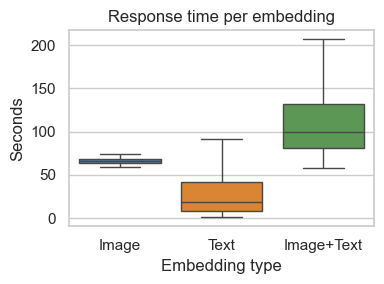

C:\Users\Jonathan\AppData\Local\Temp\ipykernel_15032\2784769512.py:16: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


Exported overleaf\graphics\pixel_energy.pdf


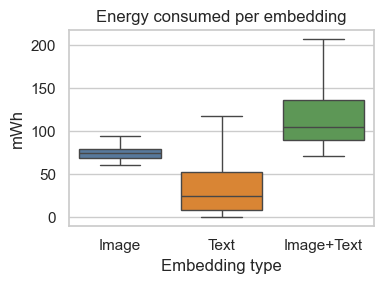

C:\Users\Jonathan\AppData\Local\Temp\ipykernel_15032\2784769512.py:16: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


Exported overleaf\graphics\pixel_peak_rss.pdf


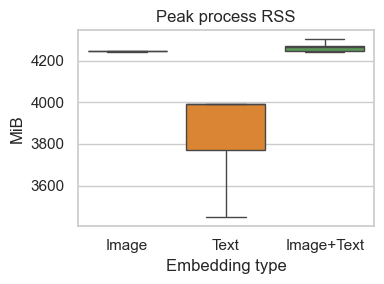

In [7]:
plot_specs = [
    ("response_time_s", "Response time per embedding", "Seconds",
     "pixel_response_time.pdf"),
    ("energy_mwh", "Energy consumed per embedding", "mWh",
     "pixel_energy.pdf"),
    ("peak_rss_mib", "Peak process RSS", "MiB",
     "pixel_peak_rss.pdf"),
]

plot_dir = Path("overleaf/graphics")
plot_dir.mkdir(parents=True, exist_ok=True)
palette = ["#4C78A8", "#F58518", "#54A24B"]
for column, title, ylabel, filename in plot_specs:
    fig, ax = plt.subplots(figsize=(4, 3))
    available = measurements.loc[measurements[column].notna()]
    sns.boxplot(
        data=available, x="embedding_type", y=column, order=EMBEDDING_ORDER,
        #hue="embedding_type",
        showfliers=False,
        palette=palette, legend=False, showmeans=False,
        meanprops={"marker": "D", "markerfacecolor": "white",
                   "markeredgecolor": "black", "markersize": 5},
        ax=ax,
    )
    #sns.stripplot(
    #    data=available, x="embedding_type", y=column, order=EMBEDDING_ORDER,
    #    color="black", alpha=0.35, size=3, jitter=0.18, ax=ax,
    #)
    counts = available.groupby("embedding_type", observed=False)[column].count()
    ax.set_xticks(range(len(EMBEDDING_ORDER)))
    ax.set_xticklabels([kind.replace("+", "+").title() for kind in EMBEDDING_ORDER])
    ax.set_title(title)
    ax.set_xlabel("Embedding type")
    ax.set_ylabel(ylabel)
    fig.tight_layout()
    output_path = plot_dir / filename
    fig.savefig(output_path, format="pdf", bbox_inches="tight")
    print(f"Exported {output_path}")
    plt.show()

## Compact comparison and interpretation notes

In [8]:
comparison = (
    measurements.groupby("embedding_type", observed=False)
    .agg(
        n=("run_id", "size"),
        median_time_s=("response_time_s", "median"),
        median_energy_mwh=("energy_mwh", "median"),
        median_power_w=("average_power_w", "median"),
        memory_n=("peak_rss_mib", "count"),
        median_peak_rss_mib=("peak_rss_mib", "median"),
        median_rss_delta_mib=("rss_delta_mib", "median"),
    )
)
display(comparison.round(3))


,n,median_time_s,median_energy_mwh,median_power_w,memory_n,median_peak_rss_mib,median_rss_delta_mib
embedding_type,,,,,,,
image,423,65.687,74.530,3.997,278,4244.390,845.166
text,423,18.213,25.113,4.754,278,3989.686,606.322
image+text,423,99.177,104.762,3.759,278,4267.031,883.019


### Measurement cautions

- Battery energy comes from Android's counter (or, in these logs, charge-counter delta multiplied by mean voltage). Its finite resolution can make short requests especially noisy.
- Average power is calculated as measured energy divided by HTTP response time. It is whole-phone draw over that window, not an isolated accelerator/model rail measurement.
- `VmRSS`/`VmHWM` are kernel process-RSS estimates, not PSS or device-wide memory. `VmHWM` includes server/model startup plus the request, while `RSS after - RSS before` estimates the request-time resident increase.
- Memory boxplots and statistics use only logs where the fields exist. Always read `memory_n`; with one or two observations per type, those values are descriptive examples rather than stable distribution estimates.
- Input screens differ in image and cleaned-JSON complexity. These plots summarize the observed workload; they do not control for input token count or image complexity.

In [10]:
from itertools import combinations

import pandas as pd
from scipy import stats
from statsmodels.stats.multitest import multipletests

EMBEDDING_ORDER = ["image", "text", "image+text"]
METRICS = ["response_time_s", "energy_mwh", "peak_rss_mib"]

def friedman_then_pairwise_wilcoxon(measurements, metrics=METRICS):
  friedman_rows = []
  pairwise_rows = []

  for metric in metrics:
      # Friedman/Wilcoxon require paired observations: retain only runs
      # that have a value for all three embedding types for this metric.
      wide = (
          measurements.pivot(index="run_id", columns="embedding_type", values=metric)
          .reindex(columns=EMBEDDING_ORDER)
          .dropna()
      )

      friedman = stats.friedmanchisquare(
          *(wide[embedding] for embedding in EMBEDDING_ORDER)
      )
      friedman_rows.append({
          "metric": metric,
          "n_paired_runs": len(wide),
          "friedman_chi2": friedman.statistic,
          "friedman_p": friedman.pvalue,
      })

      for left, right in combinations(EMBEDDING_ORDER, 2):
          result = stats.wilcoxon(
              wide[left],
              wide[right],
              alternative="two-sided",
              zero_method="wilcox",
              method="auto",
          )
          pairwise_rows.append({
              "metric": metric,
              "comparison": f"{left} vs {right}",
              "n_paired_runs": len(wide),
              "median_difference": (wide[left] - wide[right]).median(),
              "wilcoxon_statistic": result.statistic,
              "p_raw": result.pvalue,
          })

  friedman_df = pd.DataFrame(friedman_rows)
  pairwise_df = pd.DataFrame(pairwise_rows)

  # Holm correction across the three pairwise comparisons within each metric.
  pairwise_df["p_holm"] = (
      pairwise_df.groupby("metric", group_keys=False)["p_raw"]
      .transform(lambda p: multipletests(p, method="holm")[1])
  )
  pairwise_df["significant_holm_0.05"] = pairwise_df["p_holm"] < 0.05

  return friedman_df, pairwise_df


friedman_results, wilcoxon_results = friedman_then_pairwise_wilcoxon(measurements)

display(friedman_results.round(4))
display(wilcoxon_results.round(4))

,metric,n_paired_runs,friedman_chi2,friedman_p
0,response_time_s,423,728.0142,0.0
1,energy_mwh,423,684.2742,0.0
2,peak_rss_mib,278,456.2754,0.0


,metric,comparison,n_paired_runs,median_difference,wilcoxon_statistic,p_raw,p_holm,significant_holm_0.05
0,response_time_s,image vs text,423,48.2150,12832.0,0.0,0.0,True
1,response_time_s,image vs image+text,423,-32.3420,57.0,0.0,0.0,True
2,response_time_s,text vs image+text,423,-81.9910,0.0,0.0,0.0,True
3,energy_mwh,image vs text,423,50.3640,12134.0,0.0,0.0,True
4,energy_mwh,image vs image+text,423,-30.1480,923.5,0.0,0.0,True
5,energy_mwh,text vs image+text,423,-77.5900,0.0,0.0,0.0,True
6,peak_rss_mib,image vs text,278,310.2835,0.0,0.0,0.0,True
7,peak_rss_mib,image vs image+text,278,-0.6030,4486.5,0.0,0.0,True
8,peak_rss_mib,text vs image+text,278,-310.4610,0.0,0.0,0.0,True
